In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
import sklearn
from scipy.stats import chi2_contingency
from sklearn.metrics import roc_auc_score

SEED = 3132

print("Python      ", sys.version.split()[0])
print("numpy       ", np.__version__)
print("pandas      ", pd.__version__)
print("scipy       ", scipy.__version__)
print("scikit-learn", sklearn.__version__)
print("SEED        ", SEED)

Python       3.12.10
numpy        2.3.4
pandas       2.3.3
scipy        1.16.3
scikit-learn 1.7.2
SEED         3132


## 1. Stage 1 — Frame the problem

In [2]:
train = pd.read_csv("data/train.csv")
test = pd.read_csv("data/test.csv")
print("train:", train.shape, "  test:", test.shape)

only_train = sorted(set(train.columns) - set(test.columns))
only_test = sorted(set(test.columns) - set(train.columns))
print("columns only in train:", only_train)
print("columns only in test: ", only_test)

train: (32940, 22)   test: (8236, 20)
columns only in train: ['duration', 'y']
columns only in test:  []


## 2. Stage 2 — Understand the data

In [3]:
y = (train["y"] == "yes").astype(int)

print(train["y"].value_counts())
print("share of yes:               %.4f" % y.mean())
print("accuracy of 'always no':    %.4f" % (1 - y.mean()))

y
no     29229
yes     3711
Name: count, dtype: int64
share of yes:               0.1127
accuracy of 'always no':    0.8873


**How imbalanced is the target? What does "always no" score?**
3 711 of 32 940 clients (11.3 %) said "yes". Always answering "no" gives 88.7 % accuracy and finds no buyers, so accuracy is misleading here.

In [4]:
cat_cols = train.select_dtypes(exclude="number").columns.drop("y")
num_cols = train.select_dtypes(include="number").columns.drop(["id", "duration"])

# 'unknown' = missing in categorical columns
unk = pd.Series({c: int((train[c] == "unknown").sum()) for c in cat_cols})
unk = unk[unk > 0].sort_values(ascending=False)
print(pd.DataFrame({"n_unknown": unk, "share": (unk / len(train)).round(4)}))

# pdays == 999 is a sentinel ("client was not contacted before"), not a real number of days
n999 = int((train["pdays"] == 999).sum())
print("\npdays == 999: %d rows (%.1f %%)" % (n999, 100 * n999 / len(train)))
print(pd.crosstab(train["pdays"] == 999, train["poutcome"], rownames=["pdays==999"]))

           n_unknown   share
default         6871  0.2086
education       1401  0.0425
housing          794  0.0241
loan             794  0.0241
job              275  0.0083
marital           64  0.0019

pdays == 999: 31694 rows (96.2 %)
poutcome    failure  nonexistent  success
pdays==999                               
False           116            0     1130
True           3248        28446        0


**Which columns contain "missing" or "not applicable" values?**
Categorical columns use `unknown`: `default` 6 871 (20.9 %), `education` 1 401, `housing` 794, `loan` 794, `job` 275, `marital` 64. In `pdays`, the value 999 is a sentinel for "not contacted before" (31 694 rows, 96.2 %), not a number of days. Both are handled in Stage 4.

In [5]:
print("id increasing in file order:", train["id"].is_monotonic_increasing)
macro = ["emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
print(train[macro].nunique())
print(train["month"].value_counts())

id increasing in file order: True
emp.var.rate       10
cons.price.idx     26
cons.conf.idx      26
euribor3m         316
nr.employed        11
dtype: int64
month
may    10942
jul     5820
aug     4937
jun     4249
nov     3287
apr     2089
oct      559
mar      457
sep      453
dec      147
Name: count, dtype: int64


**What order are the rows in, and does my split respect it?**
The README says the rows were shuffled before `id` was assigned, so the row order means nothing and a stratified random split is fine. But time is still hidden in `month` and the macro columns (e.g. `nr.employed` has only 11 values), so a random split flatters the scores (Stage 7).

In [6]:
def cramers_v(x, target):
    t = pd.crosstab(x, target)
    chi2 = chi2_contingency(t, correction=False)[0]
    return np.sqrt(chi2 / (t.values.sum() * (min(t.shape) - 1)))

num_assoc = {}
for c in num_cols:
    auc = roc_auc_score(y, train[c])
    num_assoc[c] = max(auc, 1 - auc)          # direction-free single-feature ROC-AUC
cat_assoc = {c: cramers_v(train[c], y) for c in cat_cols}

print("Numeric features: single-feature ROC-AUC (0.5 = no signal)")
print(pd.Series(num_assoc).sort_values(ascending=False).round(3))
print("\nCategorical features: Cramer's V (0 = no relation, 1 = perfect)")
print(pd.Series(cat_assoc).sort_values(ascending=False).round(3))

Numeric features: single-feature ROC-AUC (0.5 = no signal)
nr.employed       0.750
euribor3m         0.745
emp.var.rate      0.717
previous          0.610
cons.price.idx    0.609
pdays             0.599
campaign          0.553
cons.conf.idx     0.542
age               0.509
dtype: float64

Categorical features: Cramer's V (0 = no relation, 1 = perfect)
poutcome       0.323
month          0.273
job            0.149
contact        0.144
default        0.098
education      0.069
marital        0.052
day_of_week    0.026
housing        0.011
loan           0.006
dtype: float64


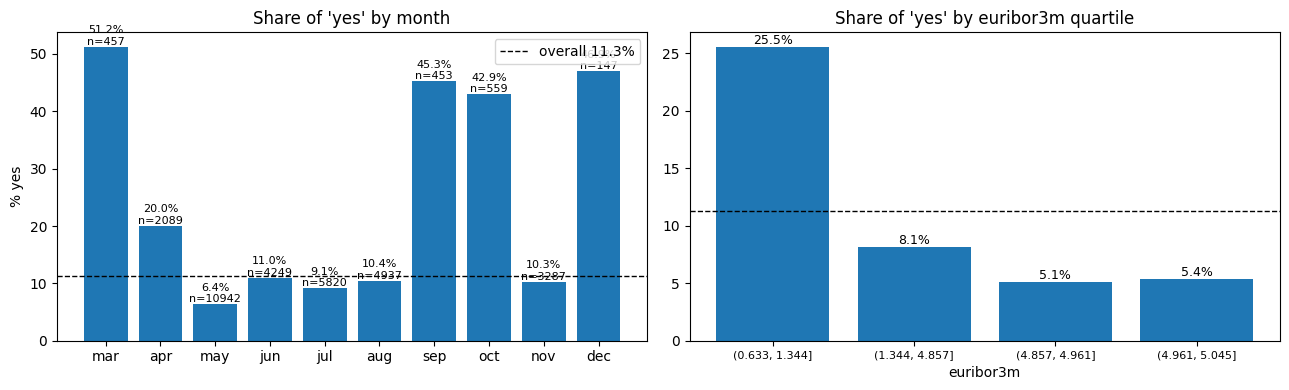

In [7]:
months = ["mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
bymonth = (train.assign(yes=y).groupby("month")["yes"].agg(["mean", "size"])
           .reindex([m for m in months if m in train["month"].unique()]))

eur_bin = pd.qcut(train["euribor3m"], 4, duplicates="drop")
byeur = train.assign(yes=y, eur=eur_bin).groupby("eur", observed=True)["yes"].agg(["mean", "size"])

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
b = ax[0].bar(bymonth.index, bymonth["mean"] * 100)
ax[0].bar_label(b, labels=["%.1f%%\nn=%d" % (m * 100, n) for m, n in zip(bymonth["mean"], bymonth["size"])], fontsize=8)
ax[0].axhline(y.mean() * 100, color="k", ls="--", lw=1, label="overall %.1f%%" % (y.mean() * 100))
ax[0].set_title("Share of 'yes' by month"); ax[0].set_ylabel("% yes"); ax[0].legend()

b = ax[1].bar([str(i) for i in byeur.index], byeur["mean"] * 100)
ax[1].bar_label(b, labels=["%.1f%%" % (m * 100) for m in byeur["mean"]], fontsize=9)
ax[1].axhline(y.mean() * 100, color="k", ls="--", lw=1)
ax[1].set_title("Share of 'yes' by euribor3m quartile"); ax[1].set_xlabel("euribor3m"); ax[1].tick_params(axis="x", labelsize=8)
plt.tight_layout(); plt.show()

**Which features are related to the answer, and by how much?**
- Numeric, single-feature ROC-AUC: `nr.employed` 0.750, `euribor3m` 0.745, `emp.var.rate` 0.717; `age` only 0.509.
- Categorical, Cramér's V: `poutcome` 0.323, `month` 0.273; `housing` 0.011, `loan` 0.006.
- Month plot: "yes" is 6.4 % in May (10 942 calls) but 43–51 % in Sep, Oct, Dec, Mar (only 147–559 calls each, so noisy).
- `euribor3m` plot: "yes" is 25.5 % in the lowest quartile and 5.1–8.1 % in the others.

## 3. Stage 3 — Design the validation
Features are the columns of `test.csv` without `id`. I put 20 % of `train.csv` aside as my hold-out (untouched until Stage 7); all comparison and tuning is cross-validation on the other 80 %.

In [8]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import make_scorer

X = train.drop(columns=["id", "y", "duration"])      # same columns as test.csv without id
assert list(X.columns) == [c for c in test.columns if c != "id"]

X_dev, X_hold, y_dev, y_hold = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)
print("development part:", X_dev.shape, " share of yes: %.4f" % y_dev.mean())
print("hold-out        :", X_hold.shape, " share of yes: %.4f" % y_hold.mean())

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)   # used for EVERY comparison

development part: (26352, 19)  share of yes: 0.1127
hold-out        : (6588, 19)  share of yes: 0.1126


**Which splitter, and why? What does the fold spread say?**
`StratifiedKFold(5, shuffle=True)`: stratified because only 11 % are "yes" (every fold keeps this share), shuffled because the row order means nothing. The same folds are used for every model. The std over the folds is the noise level: a difference smaller than it is not evidence of a better model, so I also look at per-fold differences.

## 4. Stage 4 — Preprocess inside a pipeline
All fitted steps are inside a `Pipeline` / `ColumnTransformer`. Numeric: `StandardScaler`. `pdays`: 999 becomes the median of the real values plus a 0/1 indicator. Categorical: `OneHotEncoder`; `unknown` is handled in two ways and compared below.

In [9]:
cat_cols = list(X.select_dtypes(exclude="number").columns)
num_cols = [c for c in X.columns if c not in cat_cols and c != "pdays"]
print("categorical:", cat_cols)
print("numeric    :", num_cols, "+ pdays")

def make_preprocessor(unknown="category"):
    pdays_pipe = Pipeline([
        ("imp", SimpleImputer(missing_values=999, strategy="median", add_indicator=True)),
        ("sc", StandardScaler())])
    if unknown == "category":      # option A: 'unknown' is just one more category
        cat_pipe = OneHotEncoder(handle_unknown="ignore")
    else:                          # option B: 'unknown' -> most frequent category of the training fold
        cat_pipe = Pipeline([
            ("imp", SimpleImputer(missing_values="unknown", strategy="most_frequent")),
            ("oh", OneHotEncoder(handle_unknown="ignore"))])
    return ColumnTransformer([
        ("pdays", pdays_pipe, ["pdays"]),
        ("num", StandardScaler(), num_cols),
        ("cat", cat_pipe, cat_cols)])

categorical: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']
numeric    : ['age', 'campaign', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed'] + pdays


**How do I guarantee that fitted steps see only training folds, and show it?**
The preprocessor is the first step of the pipeline passed to `cross_validate`, which fits a fresh copy on the training rows of each fold only. Evidence below: the scaler's mean equals the training-fold mean, not the mean of the whole development part.

In [10]:
import numpy as np

pipe = Pipeline([("prep", make_preprocessor("category")), ("model", LogisticRegression(max_iter=1000))])
train_idx, val_idx = next(iter(cv.split(X_dev, y_dev)))
X_tr = X_dev.iloc[train_idx]
pipe.fit(X_tr, y_dev.iloc[train_idx])

scaler = pipe.named_steps["prep"].named_transformers_["num"]
print("mean learned by the scaler        :", scaler.mean_[:3].round(5))
print("mean of the training-fold rows    :", X_tr[num_cols].mean().values[:3].round(5))
print("mean of the whole development part:", X_dev[num_cols].mean().values[:3].round(5))
assert np.allclose(scaler.mean_, X_tr[num_cols].mean().values)
assert not np.allclose(scaler.mean_, X_dev[num_cols].mean().values)
print("-> the scaler used the training fold only, not the validation fold.")
print("median used for pdays:", pipe.named_steps["prep"].named_transformers_["pdays"].named_steps["imp"].statistics_)

# the pipeline takes the raw columns of test.csv (no manual step)
print("scores for raw test.csv:", pipe.predict_proba(test.drop(columns="id")).shape)

mean learned by the scaler        : [40.09364  2.54646  0.173  ]
mean of the training-fold rows    : [40.09364  2.54646  0.173  ]
mean of the whole development part: [40.08956  2.54762  0.17365]
-> the scaler used the training fold only, not the validation fold.
median used for pdays: [6.]
scores for raw test.csv: (8236, 2)


The means match the training fold and not the whole development part, so the validation rows did not influence the scaler. The pipeline also scores the raw `test.csv` columns with no manual step.

In [11]:
def precision_at_10(y_true, y_score):
    # share of real 'yes' among the 10 % of clients with the highest score
    n = int(np.ceil(0.10 * len(y_true)))
    top = np.argsort(-np.asarray(y_score), kind="stable")[:n]
    return np.asarray(y_true)[top].mean()

scoring = {"accuracy": "accuracy",
           "roc_auc": "roc_auc",
           "avg_precision": "average_precision",
           "precision@10%": make_scorer(precision_at_10, response_method="predict_proba")}

def run_cv(model):
    out = cross_validate(model, X_dev, y_dev, cv=cv, scoring=scoring)
    return {m: out["test_" + m] for m in scoring}

def table(results):
    rows = {name: {m: "%.4f ± %.4f" % (v.mean(), v.std(ddof=1)) for m, v in r.items()}
            for name, r in results.items()}
    return pd.DataFrame(rows).T

In [12]:
res_unknown = {
    "LogReg, 'unknown' = own category": run_cv(Pipeline([("prep", make_preprocessor("category")), ("model", LogisticRegression(max_iter=1000))])),
    "LogReg, 'unknown' = imputed":      run_cv(Pipeline([("prep", make_preprocessor("impute")),   ("model", LogisticRegression(max_iter=1000))])),
}
print(table(res_unknown))

d = res_unknown["LogReg, 'unknown' = own category"]["roc_auc"] - res_unknown["LogReg, 'unknown' = imputed"]["roc_auc"]
print("\nper-fold ROC-AUC difference (own category - imputed):", d.round(4))
print("mean difference %.5f, std of the difference %.5f" % (d.mean(), d.std(ddof=1)))

                                         accuracy          roc_auc  \
LogReg, 'unknown' = own category  0.9011 ± 0.0030  0.7914 ± 0.0139   
LogReg, 'unknown' = imputed       0.9014 ± 0.0028  0.7914 ± 0.0137   

                                    avg_precision    precision@10%  
LogReg, 'unknown' = own category  0.4569 ± 0.0295  0.5028 ± 0.0308  
LogReg, 'unknown' = imputed       0.4560 ± 0.0301  0.5017 ± 0.0299  

per-fold ROC-AUC difference (own category - imputed): [ 0.0009  0.0004 -0.0018 -0.      0.0005]
mean difference 0.00000, std of the difference 0.00104


**Preprocessing decision.** `unknown` as its own category vs imputed with the most frequent value: the ROC-AUC differs by about 0.00001 (per-fold std about 0.001), which is inside the noise. I keep `unknown` as its own category: it is simpler and loses no information.

## 5. Stage 5 — Baselines
Majority-class model and logistic regression on the same folds (mean ± std over 5 folds).

In [13]:
baseline_results = {
    "Majority class (always 'no')": run_cv(Pipeline([("prep", make_preprocessor("category")), ("model", DummyClassifier(strategy="prior"))])),
    "Logistic regression":          run_cv(Pipeline([("prep", make_preprocessor("category")), ("model", LogisticRegression(max_iter=1000))])),
}
print(table(baseline_results))
print("\nlift of logistic regression in the top 10 %%: %.2f" % (baseline_results["Logistic regression"]["precision@10%"].mean() / y_dev.mean()))

                                     accuracy          roc_auc  \
Majority class (always 'no')  0.8873 ± 0.0001  0.5000 ± 0.0000   
Logistic regression           0.9011 ± 0.0030  0.7914 ± 0.0139   

                                avg_precision    precision@10%  
Majority class (always 'no')  0.1127 ± 0.0001  0.1149 ± 0.0145  
Logistic regression           0.4569 ± 0.0295  0.5028 ± 0.0308  

lift of logistic regression in the top 10 %: 4.46


| Model | accuracy | ROC-AUC | avg. precision | precision@10 % |
|---|---|---|---|---|
| Majority class | 0.887 ± 0.000 | 0.500 ± 0.000 | 0.113 ± 0.000 | 0.115 ± 0.015 |
| Logistic regression | 0.9011  ± 0.003 | 0.791 ± 0.014 | 0.457 ± 0.030 | 0.503 ± 0.031 |

- **Accuracy misleads:** "always no" already scores 88.7 %, and logistic regression adds only 1.4 points, although it ranks far better (AUC 0.79 vs 0.50; top-10 % precision about 4.5 times the base rate of 0.113).
- **The bar for Stage 6:** ROC-AUC 0.791 ± 0.014, average precision 0.457 ± 0.030, precision@10 % 0.503 ± 0.031.

## 6. Stage 6 — Compare models and tune

In [18]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

def tune(model, grid):
    pipe = Pipeline([("prep", make_preprocessor("category")), ("model", model)])
    gs = GridSearchCV(pipe, grid, cv=cv, scoring=scoring, refit=False, n_jobs=-1)
    gs.fit(X_dev, y_dev)
    return pd.DataFrame(gs.cv_results_)

def fold_scores(r, idx):
    return {m: np.array([r.loc[idx, "split%d_test_%s" % (k, m)] for k in range(cv.get_n_splits())])
            for m in scoring}

def best_row(r, mask=None):
    sub = r if mask is None else r[mask]
    return sub["mean_test_roc_auc"].idxmax()

In [19]:
grids = {
    "Logistic regression": (LogisticRegression(max_iter=2000),
        {"model__C": [0.01, 0.1, 1, 10], "model__class_weight": [None, "balanced"]}),
    "Random forest": (RandomForestClassifier(n_estimators=200, random_state=SEED),
        {"model__max_depth": [6, 12, None], "model__min_samples_leaf": [5, 20, 50],
         "model__class_weight": [None, "balanced"]}),
    "KNN": (KNeighborsClassifier(),
        {"model__n_neighbors": [25, 50, 100, 200], "model__weights": ["uniform", "distance"]}),
}
searches = {name: tune(model, grid) for name, (model, grid) in grids.items()}

best = {}
for name, r in searches.items():
    i = best_row(r)
    best[name] = (i, fold_scores(r, i))
    params = {c.replace("param_model__", ""): r.loc[i, c] for c in r.columns if c.startswith("param_")}
    print("%-20s best params: %s" % (name, params))

Logistic regression  best params: {'C': np.float64(1.0), 'class_weight': 'balanced'}
Random forest        best params: {'class_weight': 'balanced', 'max_depth': 12, 'min_samples_leaf': np.int64(5)}
KNN                  best params: {'n_neighbors': np.int64(100), 'weights': 'uniform'}


In [20]:
tuned_results = {name: scores for name, (i, scores) in best.items()}
print(table({**baseline_results, **{n + " (tuned)": s for n, s in tuned_results.items()}}))

                                     accuracy          roc_auc  \
Majority class (always 'no')  0.8873 ± 0.0001  0.5000 ± 0.0000   
Logistic regression           0.9011 ± 0.0030  0.7914 ± 0.0139   
Logistic regression (tuned)   0.8320 ± 0.0076  0.7928 ± 0.0128   
Random forest (tuned)         0.8627 ± 0.0070  0.8008 ± 0.0115   
KNN (tuned)                   0.8996 ± 0.0032  0.7909 ± 0.0100   

                                avg_precision    precision@10%  
Majority class (always 'no')  0.1127 ± 0.0001  0.1149 ± 0.0145  
Logistic regression           0.4569 ± 0.0295  0.5028 ± 0.0308  
Logistic regression (tuned)   0.4519 ± 0.0281  0.4998 ± 0.0266  
Random forest (tuned)         0.4743 ± 0.0257  0.5218 ± 0.0314  
KNN (tuned)                   0.4380 ± 0.0328  0.4862 ± 0.0207  


In [21]:
rows = {}
for name in ["Logistic regression", "Random forest"]:
    r = searches[name]
    for cw in [None, "balanced"]:
        mask = r["param_model__class_weight"].isna() if cw is None else (r["param_model__class_weight"] == cw)
        rows["%s, class_weight=%s" % (name, cw)] = fold_scores(r, best_row(r, mask))
print(table(rows))

                                                   accuracy          roc_auc  \
Logistic regression, class_weight=None      0.9011 ± 0.0030  0.7914 ± 0.0139   
Logistic regression, class_weight=balanced  0.8320 ± 0.0076  0.7928 ± 0.0128   
Random forest, class_weight=None            0.9018 ± 0.0028  0.8003 ± 0.0112   
Random forest, class_weight=balanced        0.8627 ± 0.0070  0.8008 ± 0.0115   

                                              avg_precision    precision@10%  
Logistic regression, class_weight=None      0.4569 ± 0.0295  0.5028 ± 0.0308  
Logistic regression, class_weight=balanced  0.4519 ± 0.0281  0.4998 ± 0.0266  
Random forest, class_weight=None            0.4761 ± 0.0231  0.5172 ± 0.0229  
Random forest, class_weight=balanced        0.4743 ± 0.0257  0.5218 ± 0.0314  


In [22]:
auc = {name: s["roc_auc"] for name, s in tuned_results.items()}
names = list(auc)
for i in range(len(names)):
    for j in range(i + 1, len(names)):
        d = auc[names[i]] - auc[names[j]]
        print("%-20s - %-20s  mean diff %+.4f, std of diff %.4f, folds where first is better: %d/5"
              % (names[i], names[j], d.mean(), d.std(ddof=1), (d > 0).sum()))
for name, a in auc.items():
    print("%-20s ROC-AUC per fold: %s  std over folds: %.4f" % (name, a.round(4), a.std(ddof=1)))

Logistic regression  - Random forest         mean diff -0.0080, std of diff 0.0047, folds where first is better: 0/5
Logistic regression  - KNN                   mean diff +0.0019, std of diff 0.0043, folds where first is better: 3/5
Random forest        - KNN                   mean diff +0.0099, std of diff 0.0020, folds where first is better: 5/5
Logistic regression  ROC-AUC per fold: [0.8124 0.7945 0.7935 0.7786 0.7849]  std over folds: 0.0128
Random forest        ROC-AUC per fold: [0.816  0.8058 0.7983 0.7845 0.7996]  std over folds: 0.0115
KNN                  ROC-AUC per fold: [0.8053 0.7949 0.7882 0.778  0.7881]  std over folds: 0.0100


**Conclusion.** Random forest has the highest mean ROC-AUC (0.8008 ± 0.0115) and is better than logistic regression and KNN in all 5 folds (paired differences 0.008 ± 0.005 and 0.010 ± 0.002). But these gaps are smaller than the fold std of a single model (0.010–0.013), so the advantage is small. Logistic regression and KNN are not different (0.002 ± 0.004, better in 3 of 5 folds): no winner there. I choose the random forest because it is best on every metric and consistent across folds, not because it is proven much better; logistic regression is simpler and almost as good. The best forest uses `min_samples_leaf` = 5, the smallest value in the grid, so a smaller value might help slightly.

## 7. Stage 7 — Final evaluation (once)
The hold-out was not used for any choice above. The chosen random forest is fitted on the development part and scores the hold-out once.

In [23]:
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, precision_recall_curve

final_model = Pipeline([
    ("prep", make_preprocessor("category")),
    ("model", RandomForestClassifier(n_estimators=200, max_depth=12, min_samples_leaf=5,
                                     class_weight="balanced", random_state=SEED, n_jobs=-1))])
final_model.fit(X_dev, y_dev)
score_hold = final_model.predict_proba(X_hold)[:, 1]

auc_hold = roc_auc_score(y_hold, score_hold)
ap_hold = average_precision_score(y_hold, score_hold)
print("hold-out ROC-AUC: %.4f   average precision: %.4f   (share of yes: %.4f)" % (auc_hold, ap_hold, y_hold.mean()))

hold-out ROC-AUC: 0.8072   average precision: 0.4601   (share of yes: 0.1126)


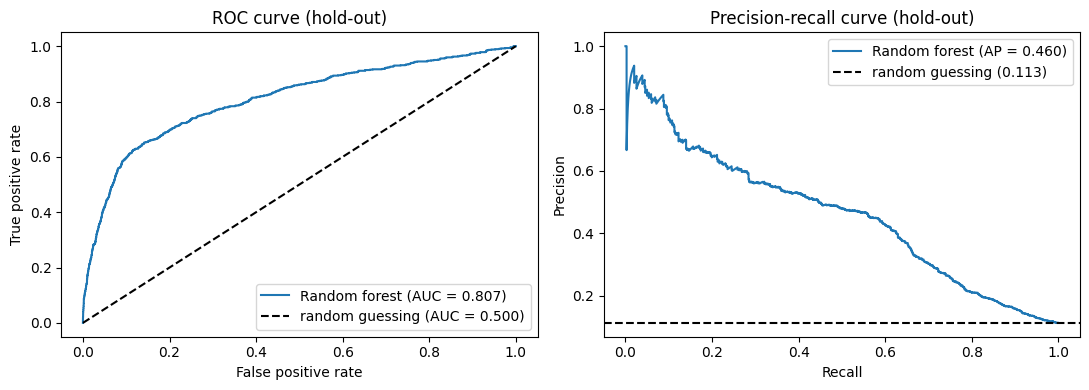

In [24]:
fpr, tpr, _ = roc_curve(y_hold, score_hold)
prec, rec, _ = precision_recall_curve(y_hold, score_hold)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(fpr, tpr, label="Random forest (AUC = %.3f)" % auc_hold)
ax[0].plot([0, 1], [0, 1], "k--", label="random guessing (AUC = 0.500)")
ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate")
ax[0].set_title("ROC curve (hold-out)"); ax[0].legend()
ax[1].plot(rec, prec, label="Random forest (AP = %.3f)" % ap_hold)
ax[1].axhline(y_hold.mean(), color="k", ls="--", label="random guessing (%.3f)" % y_hold.mean())
ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision")
ax[1].set_title("Precision-recall curve (hold-out)"); ax[1].legend()
plt.tight_layout(); plt.show()

In [25]:
from sklearn.metrics import confusion_matrix

yh = np.asarray(y_hold)
n_call = int(np.ceil(0.10 * len(yh)))
order = np.argsort(-score_hold, kind="stable")
called = np.zeros(len(yh), dtype=int)
called[order[:n_call]] = 1
cutoff = score_hold[order[n_call - 1]]

precision = yh[called == 1].mean()
recall = yh[called == 1].sum() / yh.sum()
lift = precision / yh.mean()
print("cutoff score: %.4f   clients called: %d of %d" % (cutoff, n_call, len(yh)))
print("precision@10%%: %.3f   recall@10%%: %.3f   lift over random calling: %.2f" % (precision, recall, lift))

tn, fp, fn, tp = confusion_matrix(yh, called).ravel()
print(pd.DataFrame([[tn, fp], [fn, tp]], index=["really said no", "really said yes"],
                   columns=["not called", "called"]))
print("In plain words: we phone %d clients; %d of them say yes and %d say no. "
      "%d buyers are not phoned and are missed. Random calling would give about %.0f buyers in %d calls."
      % (n_call, tp, fp, fn, n_call * yh.mean(), n_call))

cutoff score: 0.7207   clients called: 659 of 6588
precision@10%: 0.501   recall@10%: 0.445   lift over random calling: 4.45
                 not called  called
really said no         5517     329
really said yes         412     330
In plain words: we phone 659 clients; 330 of them say yes and 329 say no. 412 buyers are not phoned and are missed. Random calling would give about 74 buyers in 659 calls.


**For the call centre.** We phone the 10 % of clients with the highest score (cutoff 0.7207). Of the 659 clients we phone, 330 say yes (precision 0.501). We reach 44.5 % of all buyers (recall 0.445). Calling at random would reach only 10 % of buyers, so the lift is 4.45. The 412 buyers we do not phone are missed.

**How the random split flatters the result.** The split is random, so clients from the same months and the same economic situation are in both train and hold-out, and `month` and the macro-economic columns identify that period. In real use the model is trained on the past and scores future clients, when the economy and the campaign may be different, so the real performance is likely lower than these numbers.

## 8. Stage 8 — Save the model and write predictions
Refit on all of `train.csv`, save the pipeline with `joblib`, and write `predictions.csv` (the top 10 % of test clients get `y_pred = 1`).

In [26]:
import joblib
from sklearn.base import clone

deploy_model = clone(final_model)
deploy_model.fit(X, y)
joblib.dump(deploy_model, "model.joblib")

['model.joblib']

In [27]:
X_test = test.drop(columns="id")
test_score = deploy_model.predict_proba(X_test)[:, 1]

n_call_test = int(np.ceil(0.10 * len(test)))
order_t = np.argsort(-test_score, kind="stable")
y_pred = np.zeros(len(test), dtype=int)
y_pred[order_t[:n_call_test]] = 1

predictions = pd.DataFrame({"id": test["id"], "y_pred": y_pred, "y_score": test_score})
predictions.to_csv("predictions.csv", index=False)
print(predictions.shape, " clients to call:", predictions["y_pred"].sum())
print(predictions.head())

(8236, 3)  clients to call: 824
      id  y_pred   y_score
0  32940       0  0.218181
1  32941       0  0.189193
2  32942       0  0.280019
3  32943       0  0.322829
4  32944       0  0.235243


In [28]:
import os, subprocess, sys

check = (
    "import joblib, pandas as pd\n"
    "m = joblib.load('model.joblib')\n"
    "t = pd.read_csv('data/test.csv')\n"
    "s = m.predict_proba(t.drop(columns='id'))[:, 1]\n"
    "p = pd.read_csv('predictions.csv')\n"
    "print('loaded OK; scores agree with predictions.csv:', abs(s - p['y_score'].values).max() < 1e-9)\n"
)
out = subprocess.run([sys.executable, "-c", check], capture_output=True, text=True)
print(out.stdout, out.stderr[-500:])
print("model.joblib size: %.1f MB (limit 50 MB)" % (os.path.getsize("model.joblib") / 1e6))

loaded OK; scores agree with predictions.csv: True
 
model.joblib size: 14.4 MB (limit 50 MB)
